# Descriptive Analytics

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
data_charge = pd.read_pickle("data_charge_prep.pkl")

In [3]:
print(f"Samples for site 1: {len(data_charge[data_charge['siteID']==1])}")
print(f"Samples for site 2: {len(data_charge[data_charge['siteID']==2])}")

Samples for site 1: 32830
Samples for site 2: 30991


# Note: We have 10% more samples for site 1, than for site 2. Our model might be better to predict the values for site 1.

### Temporal Patterns and Seasonality
 Demonstrate how the number of charging events varies during
 the day, the week, and between seasons. What patterns can you observe, and how do you explain
 them?

#### Pattern during the day

Discuss: eventuell nicht nur auf connectionTime sondern gesamten Ladezyklus?

In [4]:
# data_charge[data_charge["siteID"]==2]

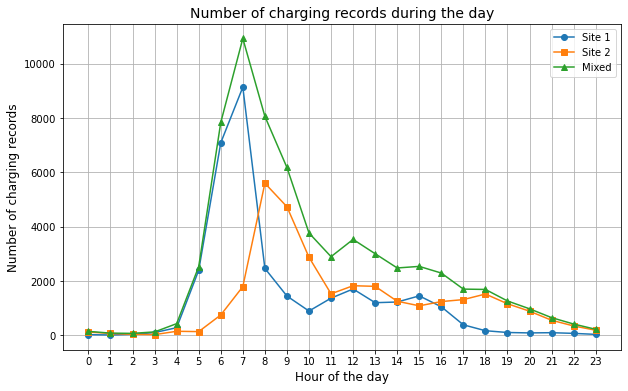

In [5]:
data_charge["hour"] = data_charge["connectionTime"].dt.hour
charging_by_hour_one = data_charge[data_charge["siteID"] == 1]["hour"].value_counts().sort_index()
charging_by_hour_two = data_charge[data_charge["siteID"] == 2]["hour"].value_counts().sort_index()
charging_by_hour_mixed = data_charge["hour"].value_counts().sort_index()

hours_list = [i for i in range(0, 24)]

plt.figure(figsize=(10, 6))
plt.plot(hours_list, charging_by_hour_one, label="Site 1", marker="o")
plt.plot(hours_list, charging_by_hour_two, label="Site 2", marker="s")
plt.plot(hours_list, charging_by_hour_mixed, label="Mixed", marker="^")

plt.title("Number of charging records during the day", fontsize=14)
plt.xlabel("Hour of the day", fontsize=12)
plt.xticks(range(0, 24))
plt.ylabel("Number of charging records", fontsize=12)
plt.legend()
plt.grid(True)
plt.show()

In [6]:
# # Backup
# charging_by_hour = data_charge["hour"].value_counts().sort_index()
# charging_by_hour_2 = charging_by_hour+2000

# # Plot
# plt.figure(figsize=(10, 6))
# plt.plot(charging_by_hour.index, charging_by_hour.values, charging_by_hour_2.values, marker="o")
# plt.title("Number of charging records during the day", fontsize=14)
# plt.xlabel("Hour of the day", fontsize=12)
# plt.ylabel("Number of charging records", fontsize=12)
# plt.grid(True)
# plt.xticks(range(0, 24))
# plt.show()

In [12]:
data_charge.columns

Index(['Unnamed: 0', 'id', 'connectionTime', 'disconnectTime',
       'doneChargingTime', 'kWhDelivered', 'sessionID', 'siteID', 'spaceID',
       'stationID', 'timezone', 'userID', 'userInputs', 'endChargingTime',
       'chargingDurationMin', 'blockingDurationMin', 'hour', 'weekday',
       'month_year', 'season'],
      dtype='object')

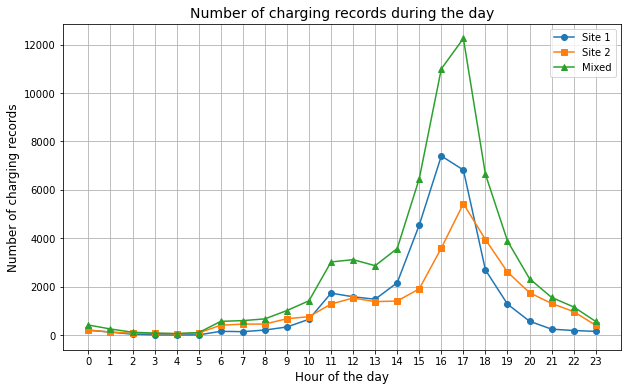

In [ ]:
# Disconnect Count
data_charge["hour"] = data_charge["disconnectTime"].dt.hour
charging_by_hour_one = data_charge[data_charge["siteID"] == 1]["hour"].value_counts().sort_index()
charging_by_hour_two = data_charge[data_charge["siteID"] == 2]["hour"].value_counts().sort_index()
charging_by_hour_mixed = data_charge["hour"].value_counts().sort_index()

hours_list = [i for i in range(0, 24)]

plt.figure(figsize=(10, 6))
plt.plot(hours_list, charging_by_hour_one, label="Site 1", marker="o")
plt.plot(hours_list, charging_by_hour_two, label="Site 2", marker="s")
plt.plot(hours_list, charging_by_hour_mixed, label="Mixed", marker="^")

plt.title("Number of charging records during the day", fontsize=14)
plt.xlabel("Hour of the day", fontsize=12)
plt.xticks(range(0, 24))
plt.ylabel("Number of charging records", fontsize=12)
plt.legend()
plt.grid(True)
plt.show()


#### Pattern during the day

In [8]:
# TODO: Auch hier differenzieren zwischen den Sites

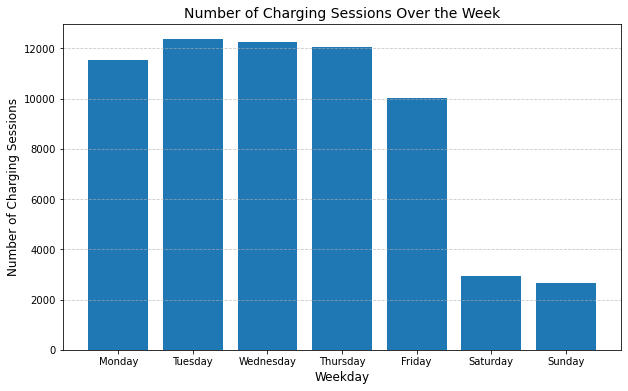

In [9]:
data_charge["weekday"] = data_charge["connectionTime"].dt.dayofweek
charging_by_weekday = data_charge["weekday"].value_counts().sort_index()
weekday_labels = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

# plot
plt.figure(figsize=(10, 6))
plt.bar(charging_by_weekday.index, charging_by_weekday.values, tick_label=weekday_labels)
plt.title("Number of Charging Sessions Over the Week", fontsize=14)
plt.xlabel("Weekday", fontsize=12)
plt.ylabel("Number of Charging Sessions", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

#### Seasonal Patterns

Hint: Normalisierung noch sinnvoll (es gibt mehr Sommer als Wintermonate im Datensatz)

c:\Users\janos\anaconda3\envs\JHNLPmitNLTK\lib\site-packages\pandas\core\arrays\datetimes.py:1092: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  UserWarning,


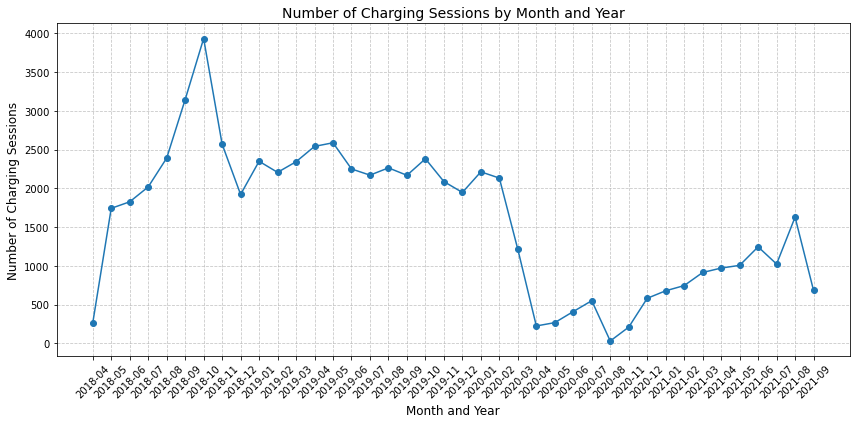

In [10]:
data_charge["month_year"] = data_charge["connectionTime"].dt.to_period("M")
charging_by_month_year = data_charge["month_year"].value_counts().sort_index()

# plot
plt.figure(figsize=(12, 6))
plt.plot(charging_by_month_year.index.astype(str), charging_by_month_year.values, marker="o")
plt.title("Number of Charging Sessions by Month and Year", fontsize=14)
plt.xlabel("Month and Year", fontsize=12)
plt.ylabel("Number of Charging Sessions", fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

We can see that the start of the charging session recording is in April 2018 and ends in September 2021, which is why not every month occurs equally often and we therefore have to normalise. We also see a gap between 08/2020 and 11/2020.

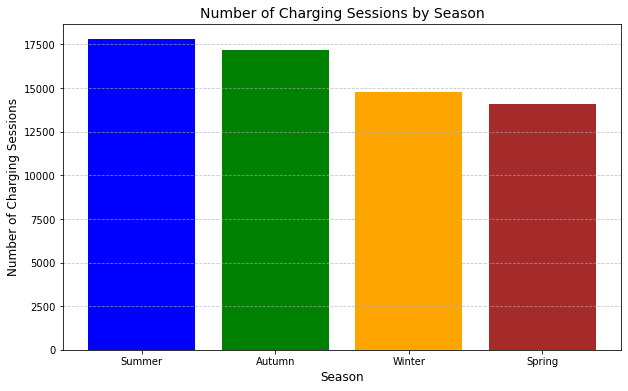

In [11]:
# Create a new column: Determine the season
def get_season(date):
    month = date.month
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    elif month in [9, 10, 11]:
        return "Autumn"


data_charge["season"] = data_charge["connectionTime"].apply(get_season)
charging_by_season = data_charge["season"].value_counts()

#  plot
plt.figure(figsize=(10, 6))
plt.bar(
    charging_by_season.index, charging_by_season.values, color=["blue", "green", "orange", "brown"]
)
plt.title("Number of Charging Sessions by Season", fontsize=14)
plt.xlabel("Season", fontsize=12)
plt.ylabel("Number of Charging Sessions", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()